# Анализ продаж авиабилетов

### Задачи
1. Познакомьтесь с данными.
2. Осуществите предобработку данных.
    - 2.1 Приведите заголовки к удобному виду.
    - 2.2 Проверьте типы данных.
    - 2.3 Обработайте пропуски.
    - 2.4 Проверьте наличие дубликатов.
    - 2.5 Исключите нулевые значения в выручке для дальнейшего исследования. 
3. Исследовательский анализ данных:
     - 3.1 Создайте отчет о динамике продаж (выручке). Постройте линейный график. Повторите отчет с детализацией по полям: FFP_FLAG, ROUTE_FLIGHT_TYPE, SALE_TYPE. Постройте общие отчеты по выручке по типам пассажиров, по типам перелета, по способам покупки, по программам лояльности. Визуализируйте каждый отчет. Решение о детализации отчетов примите самостоятельно.
     - 3.2 Исследуйте выручку, примите решение об исключении выбросов для дальнейшего исследования, руководствуясь минимизацией потерь в данных.
     - 3.3 Исследуйте сезонность продаж. Дополнительно проверьте гипотезу о том, что выручка от продаж осенью и зимой отличается. Исследуйте выручку и число продаж по месяцам, проверьте корреляцию.
     - 3.4 Клиенты покупают билеты в разное время. Кто-то покупает билеты заранее, другие - в последний момент. Проверьте гипотезу о том, что выручка от продажи билетов для этих двух групп клиентов отличается. Предварительно разбейте клиентов минимум на три группы.
     - 3 .5  Определите топ-10 популярных направлений перелета (город-город) отдельно для ВМЛ и МВЛ. Изучите выручку для этих направлений. Для этого добавьте в датасет сведения о городах, используя данные из датасета:
     https://raw.githubusercontent.com/jpatokal/openflights/master/data/airports.dat
     - 3.6 Определите есть ли зависимость выручки от других признаков. Постройте матрицу корреляций.

Каждый пункт исследования сопроводите выводами.


In [1]:
# импортируем библиотеки
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import t, norm
from scipy import stats as st

In [2]:
df = pd.read_csv('air_data.csv', sep=';')

In [3]:
df.columns = df.columns.str.lower()

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   issue_date         50000 non-null  object
 1   flight_date_loc    50000 non-null  object
 2   pax_type           50000 non-null  object
 3   revenue_amount     50000 non-null  int64 
 4   orig_city_code     49998 non-null  object
 5   dest_city_code     49999 non-null  object
 6   route_flight_type  50000 non-null  object
 7   ffp_flag           19398 non-null  object
 8   sale_type          50000 non-null  object
dtypes: int64(1), object(8)
memory usage: 3.4+ MB


In [5]:
df.isna().sum()

issue_date               0
flight_date_loc          0
pax_type                 0
revenue_amount           0
orig_city_code           2
dest_city_code           1
route_flight_type        0
ffp_flag             30602
sale_type                0
dtype: int64

**Первые выводы:**
Данные содержат 9 столбцов и 50 000 строк.

**Пропуски:**
1. Значительные пропуски содержатся в столбце ffp_flag (30602 пропусков)
2. В столбце orig_city_code (2 пропуска)
3. В столбце dest_city_code (1 пропуск)

**Типы данных:**
1. Столбцы issue_date и flight_date_loc должны иметь тип данных datetime
2. Столбец route_flight_type содержит значения на русском языке ['ВВЛ', 'МВЛ']


In [6]:
df.loc[5000:10000]

,issue_date,flight_date_loc,pax_type,revenue_amount,orig_city_code,dest_city_code,route_flight_type,ffp_flag,sale_type
5000,2022-01-04 00:00:00,2022-01-18 00:00:00,AD,480,FEG,STW,МВЛ,NaN,OFFLINE
5001,2022-01-03 00:00:00,2022-01-16 00:00:00,AD,260,MOW,SIP,ВВЛ,NaN,OFFLINE
5002,2021-12-25 00:00:00,2022-01-07 00:00:00,AD,630,ALC,MOW,МВЛ,NaN,ONLINE
5003,2021-12-16 00:00:00,2022-01-18 00:00:00,AD,140,MOW,KUF,ВВЛ,FFP,ONLINE
5004,2021-12-27 00:00:00,2022-01-08 00:00:00,AD,260,VOZ,MOW,ВВЛ,NaN,ONLINE
...,...,...,...,...,...,...,...,...,...
9996,2022-04-25 00:00:00,2022-04-28 00:00:00,AD,370,MRV,MOW,ВВЛ,NaN,OFFLINE
9997,2022-04-07 00:00:00,2022-04-20 00:00:00,AD,500,OVB,MOW,ВВЛ,NaN,OFFLINE
9998,2022-04-25 00:00:00,2022-04-28 00:00:00,AD,350,MOW,UFA,ВВЛ,NaN,OFFLINE
9999,2022-04-19 00:00:00,2022-04-19 00:00:00,AD,200,MOW,LED,ВВЛ,FFP,ONLINE


In [7]:
#приводим тип данных к правильному datetime
df['issue_date'] = pd.to_datetime(df['issue_date'], format='%Y-%m-%d %H:%M:%S')
df['flight_date_loc'] = pd.to_datetime(df['flight_date_loc'], format='%Y-%m-%d %H:%M:%S')

In [8]:
#заменили значения на англоязычные
df = df.replace(['МВЛ', 'ВВЛ'],['INF', 'DOF'])

INF - international flights (МВЛ)

DOF - domestic flights (ВВЛ)

***Обработка пропусков***

In [9]:
df['ffp_flag'].unique()

array([nan, 'FFP'], dtype=object)

FFP - есть программа лояльности, а пропуски - нет программы лояльности

Зададим категориальную переменную в численном виде, заменив пропуски на 0, FFP на 1.

In [10]:
df['ffp_flag'] = df['ffp_flag'].fillna(0)
df['ffp_flag'] = df['ffp_flag'].replace(['FFP'], 1)

In [11]:
df[df['orig_city_code'].isna() == True]

,issue_date,flight_date_loc,pax_type,revenue_amount,orig_city_code,dest_city_code,route_flight_type,ffp_flag,sale_type
2020,2022-02-17,2022-03-22,AD,440,NaN,KHV,INF,0,ONLINE
8100,2022-05-02,2022-05-11,AD,440,NaN,KHV,INF,0,OFFLINE


Не можем заполнить пропуски в столбцах orig_city_code и dest_city_code, количество данных незначительно, следовательно, можем удалить их.

In [12]:
df.dropna(subset=['orig_city_code'], inplace=True)
df.dropna(subset=['dest_city_code'], inplace=True)

***Проверка наличия дубликатов***

In [13]:
df.duplicated().sum()

169

In [14]:
df.loc[df.duplicated(keep=False)]

,issue_date,flight_date_loc,pax_type,revenue_amount,orig_city_code,dest_city_code,route_flight_type,ffp_flag,sale_type
337,2021-10-29,2021-11-12,AD,220,MOW,KZN,DOF,1,ONLINE
338,2021-10-29,2021-11-12,AD,220,MOW,KZN,DOF,1,ONLINE
649,2022-02-11,2022-08-03,AD,580,PKC,OVB,DOF,0,OFFLINE
670,2022-02-11,2022-08-03,AD,580,PKC,OVB,DOF,0,OFFLINE
716,2022-02-08,2022-08-01,AD,360,MMK,MOW,DOF,0,OFFLINE
...,...,...,...,...,...,...,...,...,...
49360,2022-03-30,2022-05-03,AD,410,MOW,OVB,DOF,1,ONLINE
49424,2022-03-30,2022-05-03,AD,410,MOW,OVB,DOF,1,ONLINE
49677,2022-04-02,2022-05-02,AD,470,NUX,MOW,DOF,0,ONLINE
49968,2022-06-28,2022-06-30,AD,950,MOW,HTA,DOF,0,OFFLINE


Обнаружили 169 явных дубликатов, удаляем их.

In [15]:
df.drop_duplicates(inplace=True)

In [16]:
#удаляем нулевые значения в выручке для дальнейшего исследования
#df[df['revenue_amount'] == 0]

In [17]:
df = df.drop(df[df['revenue_amount'] == 0].index).reset_index(drop= True)

In [18]:
df

,issue_date,flight_date_loc,pax_type,revenue_amount,orig_city_code,dest_city_code,route_flight_type,ffp_flag,sale_type
0,2021-12-07,2022-01-11,AD,200,MOW,KGD,DOF,0,ONLINE
1,2021-12-31,2022-01-03,AD,610,UUS,OVB,DOF,0,OFFLINE
2,2021-11-28,2022-01-04,AD,390,KGD,MOW,DOF,1,ONLINE
3,2021-12-08,2022-01-05,AD,190,VOZ,MOW,DOF,0,ONLINE
4,2021-12-08,2022-01-12,AD,190,MOW,KRR,DOF,1,OFFLINE
...,...,...,...,...,...,...,...,...,...
49357,2022-06-11,2022-06-22,CHD,480,MOW,OMS,DOF,0,ONLINE
49358,2022-06-06,2022-06-20,AD,270,LED,MOW,DOF,0,OFFLINE
49359,2022-06-26,2022-06-29,AD,230,MOW,KZN,DOF,1,ONLINE
49360,2022-06-26,2022-06-28,AD,270,KZN,MOW,DOF,0,OFFLINE


**Предобработка данных завершена. Можем перейти к анализу данных**

<div class="alert alert-success">

Комментарий от преподавателя:
    
Отлично! <br>
Удаляем нулевые значения в выручке для дальнейшего исследования: Альтернативно: <br>
df = df.query('revenue_amount != 0').reset_index(drop=True)

## Исследовательский анализ данных

Для формирования отчета о динамике выручки отсортируем данные по дате и сгруппируем по дате и по месяцам.

In [19]:
new_df = df.sort_values(by='issue_date').reset_index(drop= True)

In [20]:
#создаем отчет о динамике выручки по дате
report = new_df.groupby('issue_date')['revenue_amount'].sum().to_frame()
report

,revenue_amount
issue_date,
2021-10-01,60310
2021-10-02,33100
2021-10-03,34320
2021-10-04,58190
2021-10-05,60800
...,...
2022-09-26,39520
2022-09-27,48350
2022-09-28,44860


In [21]:
#исправление
report = new_df.groupby('issue_date')['revenue_amount'].sum().reset_index()
report

,issue_date,revenue_amount
0,2021-10-01,60310
1,2021-10-02,33100
2,2021-10-03,34320
3,2021-10-04,58190
4,2021-10-05,60800
...,...,...
360,2022-09-26,39520
361,2022-09-27,48350
362,2022-09-28,44860
363,2022-09-29,27460


<AxesSubplot:title={'center':'Динамика продаж по дате'}, xlabel='Дата', ylabel='Сумма продаж'>

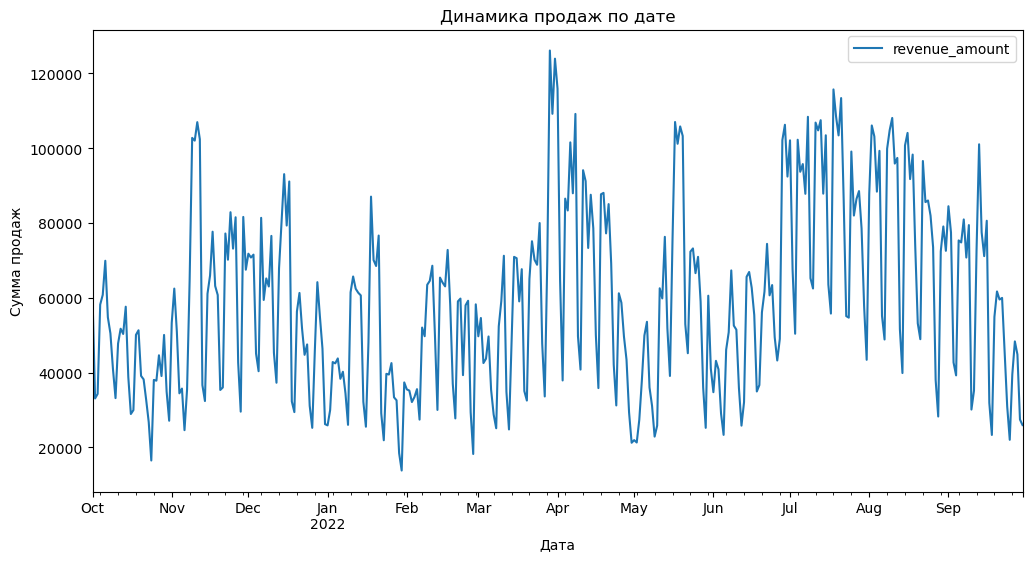

In [22]:
report.plot(figsize=(12, 6),
            x='issue_date',
            y='revenue_amount',
            title='Динамика продаж по дате',
            ylabel='Сумма продаж',
            xlabel='Дата')

Для более комфортного восприятия информации сгруппируем данные по месяцам в report_1 

In [23]:
#в новом дф создаем столбец с месяцем и годом
new_df['year_month'] = new_df['issue_date'].dt.to_period('M')

#группируем по месяцам и находим сумму выручки => получаем отчет 
report_1 = new_df.groupby('year_month')['revenue_amount'].sum().reset_index(name='revenue_sum') #to_frame()
report_1

,year_month,revenue_sum
0,2021-10,1327840
1,2021-11,1851260
2,2021-12,1757250
3,2022-01,1352390
4,2022-02,1347770
5,2022-03,1826430
6,2022-04,2032570
7,2022-05,1713360
8,2022-06,1614500
9,2022-07,2638430


<AxesSubplot:title={'center':'Динамика продаж по месяцам'}, xlabel='Месяцы', ylabel='Сумма продаж в млн'>

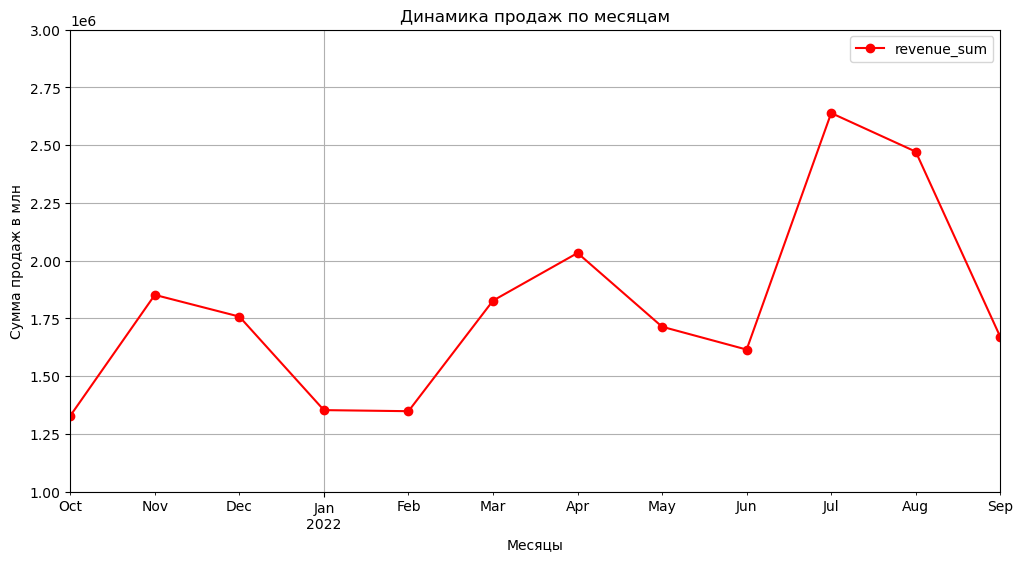

In [24]:
report_1.plot(x='year_month',
              y='revenue_sum',
              style='o-',
              color='r',
              grid=True,
              figsize=(12, 6),
              ylim=(1000000, 3000000),
              title='Динамика продаж по месяцам',
              ylabel='Сумма продаж в млн',
              xlabel='Месяцы')

In [25]:
new_df.head()

,issue_date,flight_date_loc,pax_type,revenue_amount,orig_city_code,dest_city_code,route_flight_type,ffp_flag,sale_type,year_month
0,2021-10-01,2021-10-04,AD,370,OVB,LED,DOF,1,ONLINE,2021-10
1,2021-10-01,2021-10-04,AD,390,KUF,MOW,DOF,1,ONLINE,2021-10
2,2021-10-01,2021-10-02,AD,840,OVB,VVO,DOF,1,OFFLINE,2021-10
3,2021-10-01,2021-10-31,AD,330,UUD,OVB,DOF,1,ONLINE,2021-10
4,2021-10-01,2021-10-10,AD,340,VOZ,MOW,DOF,0,OFFLINE,2021-10


In [26]:
report_2 = report_1.copy(deep=True) #копирую report_1 для нового детализированного отчета в report_2

In [27]:
report_try = new_df.groupby('year_month')['ffp_flag'].sum().tolist()
report_try

[1420, 2161, 1933, 1507, 1324, 1913, 1512, 1400, 1227, 1906, 1798, 1235]

In [28]:
report_2['ffp_amount'] = pd.Series([1420, 2161, 1933, 1507, 1324, 1913, 1512, 1400, 1227, 1906, 1798, 1235])

In [29]:
#детализируем отчет, добавляя столбцы по типам прелета

#столбец с количеством domestic flights в каждом месяце
rep_dof_list = new_df[new_df['route_flight_type'] == 'DOF'].groupby('year_month')['route_flight_type'].count().tolist()
report_2['dof_type_amount'] = pd.Series(rep_dof_list)

#столбец с количеством international flights в каждом месяце
rep_inf_list = new_df[new_df['route_flight_type'] == 'INF'].groupby('year_month')['route_flight_type'].count().tolist()
report_2['inf_type_amount'] = pd.Series(rep_inf_list)

In [30]:
#также детализируем отчет, добавляя столбцы по способу покупки

#столбец с количеством online покупок в каждом месяце
online_list = new_df[new_df['sale_type'] == 'ONLINE'].groupby('year_month')['sale_type'].count().tolist()
report_2['online_amount'] = pd.Series(online_list)

#столбец с количеством offline покупок в каждом месяце
offline_list = new_df[new_df['sale_type'] == 'OFFLINE'].groupby('year_month')['sale_type'].count().tolist()
report_2['offline_amount'] = pd.Series(offline_list)

In [31]:
#добавляю столбец с общим количеством пассажиров в месяц
am_pas = new_df.groupby('year_month')['pax_type'].count().tolist()
report_2['passangers_number'] = pd.Series(am_pas)

Получили очень наглядный отчет по колличеству каждого типа в каждом месяце, с помощью которого можно отследить динамику 

In [32]:
report_2

,year_month,revenue_sum,ffp_amount,dof_type_amount,inf_type_amount,online_amount,offline_amount,passangers_number
0,2021-10,1327840,1420,3053,562,2028,1587,3615
1,2021-11,1851260,2161,4548,624,2934,2238,5172
2,2021-12,1757250,1933,3963,602,2566,1999,4565
3,2022-01,1352390,1507,3195,394,2100,1489,3589
4,2022-02,1347770,1324,3132,321,1885,1568,3453
5,2022-03,1826430,1913,4247,79,2607,1719,4326
6,2022-04,2032570,1512,3765,209,2053,1921,3974
7,2022-05,1713360,1400,3451,170,2184,1437,3621
8,2022-06,1614500,1227,3160,193,1860,1493,3353
9,2022-07,2638430,1906,4998,261,3068,2191,5259


<AxesSubplot:title={'center':'Динамика изменения соотношения типов по месяцам'}, xlabel='Месяцы', ylabel='Количество пассажиров'>

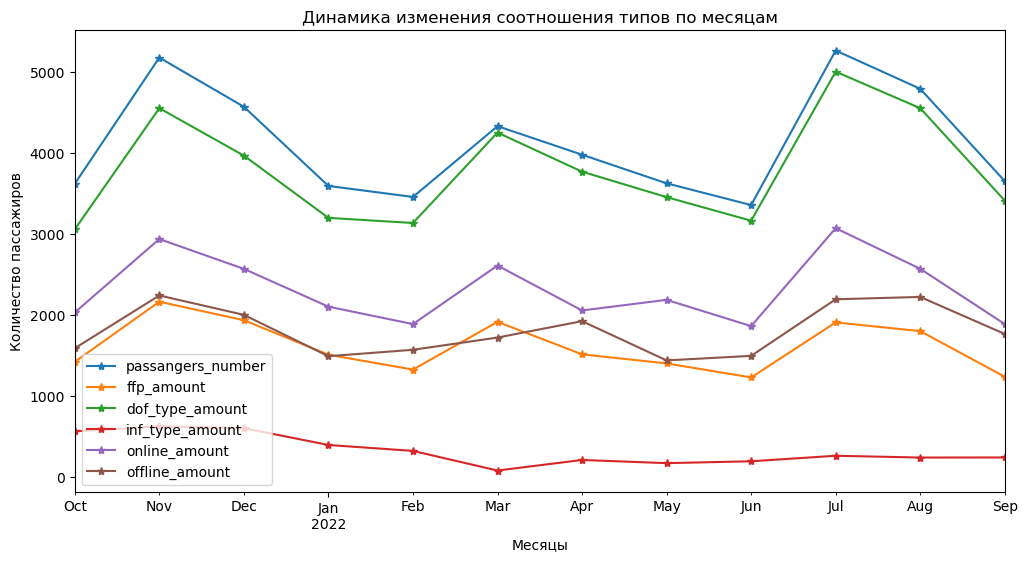

In [33]:
report_2.plot(x='year_month',
              y=['passangers_number', 'ffp_amount', 'dof_type_amount', 'inf_type_amount', 'online_amount', 'offline_amount'],
              figsize=(12,6),
              style='*-',
              title='Динамика изменения соотношения типов по месяцам',
              ylabel='Количество пассажиров',
              xlabel='Месяцы')

**Общие отчеты по выручке и типам пассажиров/типам перелета/способам покупки/программе лояльности и их визуализация**

Общий отчет о выручке по pax_type
  pax_type  revenue_sum
0       AD     20259210
1      CHD      1333430
2      INF         9730

Общий отчет о выручке по route_flight_type
  route_flight_type  revenue_sum
0               DOF     19610480
1               INF      1991890

Общий отчет о выручке по sale_type
  sale_type  revenue_sum
0   OFFLINE     10316900
1    ONLINE     11285470

Общий отчет о выручке по ffp_flag
   ffp_flag  revenue_sum
0         0     13379980
1         1      8222390



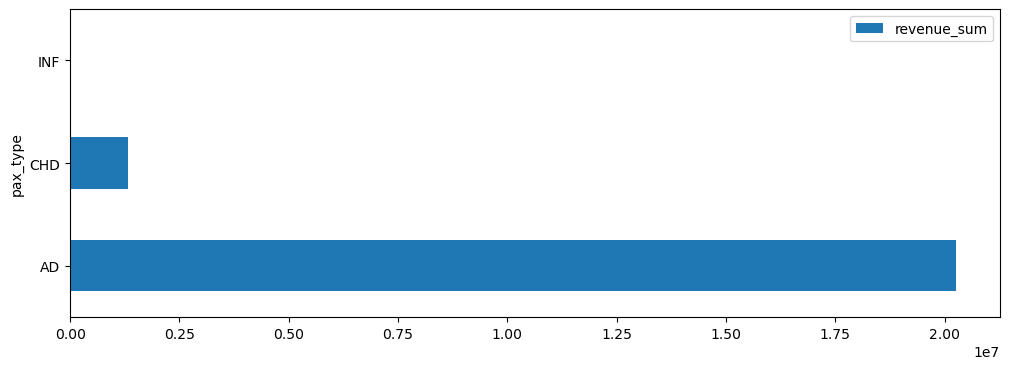

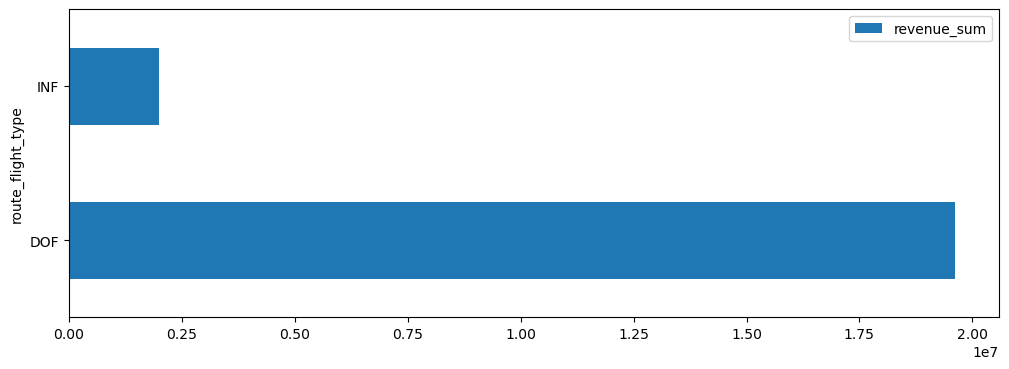

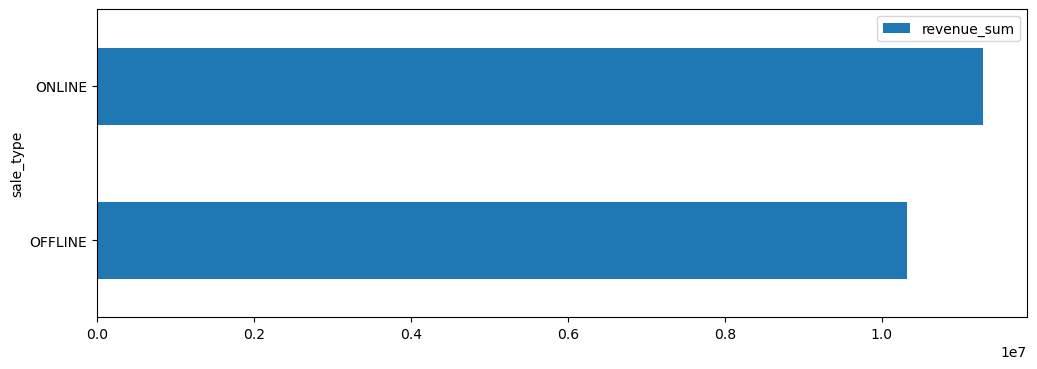

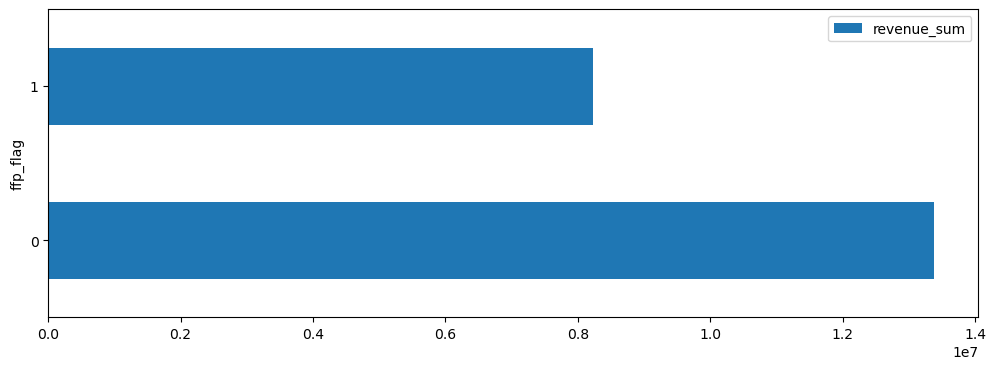

In [35]:
#исправление
#общие отчеты о выручке

col_name_list = ['pax_type', 'route_flight_type', 'sale_type', 'ffp_flag']
#title_plot_list = ['Выручка по типам пассажиров, 10млн', 'Выручка по типам перелета, 10млн', 'Выручка по способам покупки, 10млн', 'Выручка по наличию программы лояльности, 10млн']
#x_lb_list = ['Типы пассажиров', 'Типы перелетов', 'Типы способов покупки', 'Наличие/отсутсивие программы лояльности']
#color_list = ['g', 'm', 'c', 'b']

for i in col_name_list:
    
    rep = new_df.groupby(i)['revenue_amount'].sum().reset_index(name='revenue_sum')
    print('Общий отчет о выручке по', i)
    print(rep)
    print()
    rep.plot(kind='barh',
             x=i,
             y='revenue_sum',
             figsize=(12, 4))

<AxesSubplot:title={'center':'Выручка по типам перелета, 10млн'}, ylabel='Типы перелетов'>

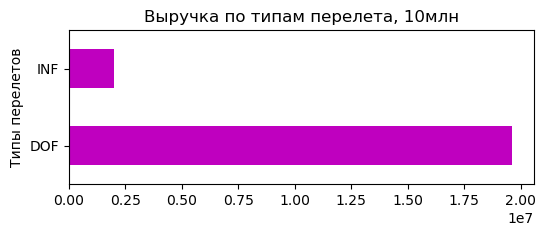

In [36]:
#прошлый варианты
r2 = new_df.groupby('route_flight_type')['revenue_amount'].sum().reset_index(name='revenue_sum')

r2.plot(kind='barh',
        x='route_flight_type',
        y='revenue_sum',
        figsize=(6, 2),
        title='Выручка по типам перелета, 10млн',
        xlabel='Типы перелетов',
        legend=False,
        color='m')

#в цикле не получилось задать цвет графика и названия осей как здесь

### Перейдем к исследованию выручки

In [37]:
df.head()

,issue_date,flight_date_loc,pax_type,revenue_amount,orig_city_code,dest_city_code,route_flight_type,ffp_flag,sale_type
0,2021-12-07,2022-01-11,AD,200,MOW,KGD,DOF,0,ONLINE
1,2021-12-31,2022-01-03,AD,610,UUS,OVB,DOF,0,OFFLINE
2,2021-11-28,2022-01-04,AD,390,KGD,MOW,DOF,1,ONLINE
3,2021-12-08,2022-01-05,AD,190,VOZ,MOW,DOF,0,ONLINE
4,2021-12-08,2022-01-12,AD,190,MOW,KRR,DOF,1,OFFLINE


In [38]:
df['revenue_amount'].describe()

count    49362.000000
mean       437.631579
std        214.611412
min         10.000000
25%        290.000000
50%        400.000000
75%        550.000000
max       5200.000000
Name: revenue_amount, dtype: float64

<AxesSubplot:>

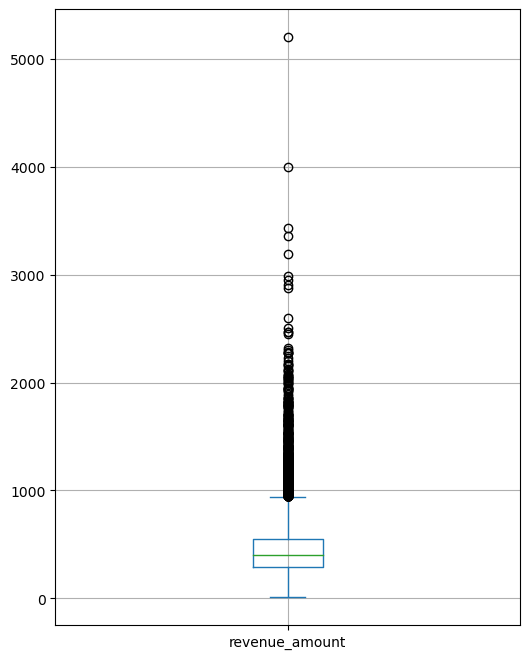

In [39]:
#построим диаграмму размаха
df['revenue_amount'].plot(kind='box', figsize=(6, 8), grid=True)

Исходя из диаграммы размаха можно сделать вывод о наличии большого хвоста из выбросов, причем выбросы плотно сгруппированы в диапазоне значений примерно от 900 до 2400. 

Медианное значение равно 400\
Минимальное = 10\
Максимальное = 5200

In [40]:
#рассчитаем межквартильный размах iqr
q75 = np.percentile(df['revenue_amount'], 75)
q25 = np.percentile(df['revenue_amount'], 25)
iqr = q75 - q25
ejection_h = q75 + iqr * 1.5
ejection_l = q25 - iqr * 1.5

print(f'Межквартильный размах равен {iqr}; Выбросы находятся выше {ejection_h} и ниже {ejection_l}')

Межквартильный размах равен 260.0; Выбросы находятся выше 940.0 и ниже -100.0


Значение ejection_l получилось отрицательным, значит выбросов внизу нет, выбросы только выше значения 940.\
Теперь рассчитаем количество выбросов.

In [41]:
n_ejection = df['revenue_amount'][df['revenue_amount'] > ejection_h].count()
print('Число выбросов:', n_ejection)

Число выбросов: 987


***У нас обнаружено всего 987 выбросов, которые находятся выше значения 940 и до значения 5200.***\
Для дальнейшего исследования необходимо исключить выбросы. Но какие значения стоит исключить, а какие лучше оставить?\
Руководствуясь минимизацией потерь данных, я считаю, что не стоит удалять все выбросы. Если еще раз посмотреть на диаграмму размаха, то можно увидеть, что хвост из выбросов в начале очень плотный, а ближе к максимальному значению он рассеивается.\
Кроме того, так как мы исследуем выручку, эти выбросы могут быть связаны с подорожанием билетов на какой-либо рейс или какими-либо доп услугами (возможно, доп плата за багаж и тд) (честно говоря, не знаю, как это проверить), поэтому я решила посмотреть как распределены выбросы с помощью гистограммы.\
***Мы видим, что бОльшая часть выбросов находится в промежутке от 940 до примерно 1500. Рассчитаем количество. Получается 843 выброса из 987 (общее число выбросов) не превышает значение 1500.*** Я считаю, что нужно исключить выбросы, которые превышают 1500, а остальное оставить, так как могут быть свои причины на то, что получились такие значения и их исключение приведет к неточному исследованию данных. 


<AxesSubplot:>

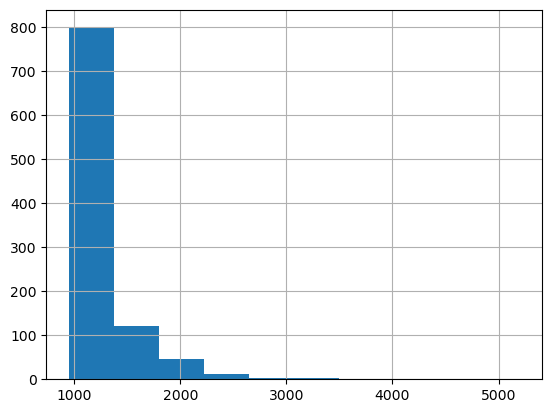

In [42]:
df['revenue_amount'][df['revenue_amount'] > ejection_h].hist() 

In [43]:
df['revenue_amount'][(df['revenue_amount'] > ejection_h) & (df['revenue_amount'] < 1500)].count()

843

In [44]:
#исключаем выбросы выше значения 1500 и получаем новый рабочий датафрейм dfo без выбросов
dfo = df[df['revenue_amount'] < 1500]

In [45]:
dfo['revenue_amount'].describe() #проверка 

count    49218.000000
mean       433.300215
std        197.590256
min         10.000000
25%        290.000000
50%        400.000000
75%        550.000000
max       1490.000000
Name: revenue_amount, dtype: float64

In [46]:
new_dfo = new_df[new_df['revenue_amount'] < 1500].reset_index(drop= True)

<AxesSubplot:>

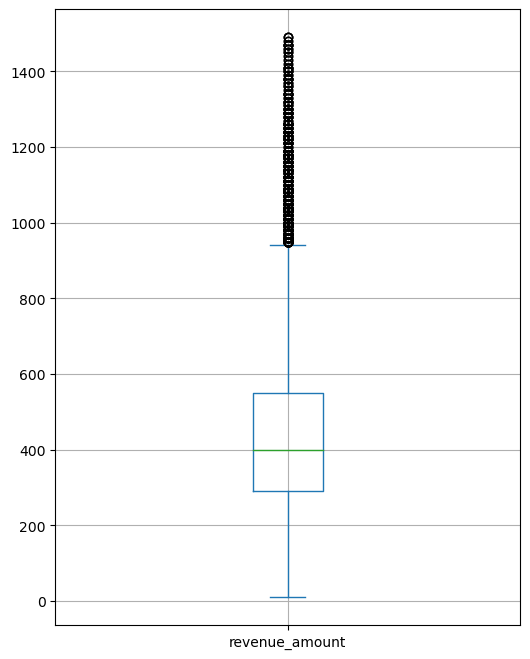

In [47]:
#исправление
new_dfo['revenue_amount'].plot(kind='box', figsize=(6, 8), grid=True)

### Исследуем сезонность продаж

In [48]:
# воспользуемся рабочим датафреймом new_df, в котором уже есть столбец year_month
new_dfo.head()

,issue_date,flight_date_loc,pax_type,revenue_amount,orig_city_code,dest_city_code,route_flight_type,ffp_flag,sale_type,year_month
0,2021-10-01,2021-10-04,AD,370,OVB,LED,DOF,1,ONLINE,2021-10
1,2021-10-01,2021-10-04,AD,390,KUF,MOW,DOF,1,ONLINE,2021-10
2,2021-10-01,2021-10-02,AD,840,OVB,VVO,DOF,1,OFFLINE,2021-10
3,2021-10-01,2021-10-31,AD,330,UUD,OVB,DOF,1,ONLINE,2021-10
4,2021-10-01,2021-10-10,AD,340,VOZ,MOW,DOF,0,OFFLINE,2021-10


In [49]:
#не поняла, как правильно исследовать сезонность продаж
#не вижу других вариантов, кроме группировки выручки по месяцам как в 1 задании eda (только теперь без выбросов)

mon_report = new_dfo.groupby('year_month')['revenue_amount'].sum().reset_index(name='revenue_sum')

rev_num_list = new_dfo.groupby('year_month')['revenue_amount'].count().tolist()
mon_report['sales_number'] = pd.Series(rev_num_list)

In [50]:
#получили отчет суммы продаж и количества продаж в каждом месяце
mon_report

,year_month,revenue_sum,sales_number
0,2021-10,1311370,3606
1,2021-11,1818840,5156
2,2021-12,1733500,4553
3,2022-01,1332620,3578
4,2022-02,1331100,3444
5,2022-03,1803070,4314
6,2022-04,2015840,3965
7,2022-05,1710130,3619
8,2022-06,1602410,3347
9,2022-07,2614150,5245


In [51]:
#рассчитаем корреляцию
#mon_report.corr()
mon_report['revenue_sum'].corr(mon_report['sales_number'])

0.77322827642844

***Вывод:***\
Значение коэффициента корреляции равно 0.7732, следовательно, сила связи между переменными **высокая** (так как от 0,7 до 0,9).\
Значит, очевидно, между количеством продаж и суммой продаж высокая степень связи.

Для наглядности еще раз построим графики 

<AxesSubplot:title={'center':'Динамика суммы продаж по месяцам'}, xlabel='Месяцы', ylabel='Сумма продаж в млн'>

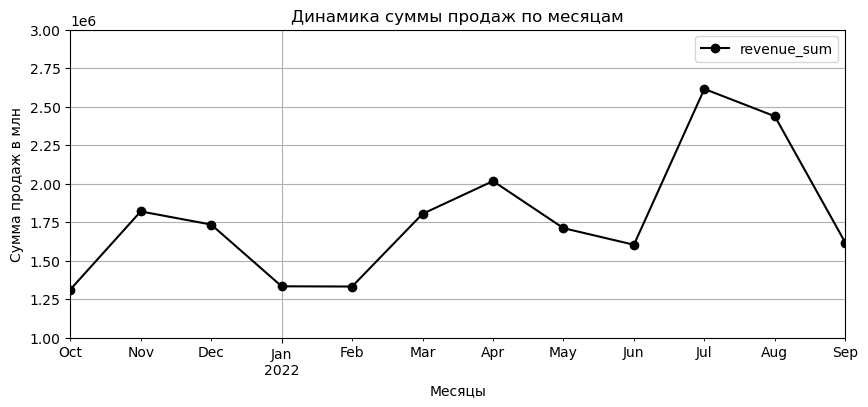

In [52]:
mon_report.plot(x='year_month',
                y='revenue_sum',
                style='o-',
                color='k',
                grid=True,
                figsize=(10, 4),
                ylim=(1000000, 3000000),
                title='Динамика суммы продаж по месяцам',
                ylabel='Сумма продаж в млн',
                xlabel='Месяцы')

<AxesSubplot:title={'center':'Динамика количества продаж по месяцам'}, xlabel='Месяцы', ylabel='Количество продаж'>

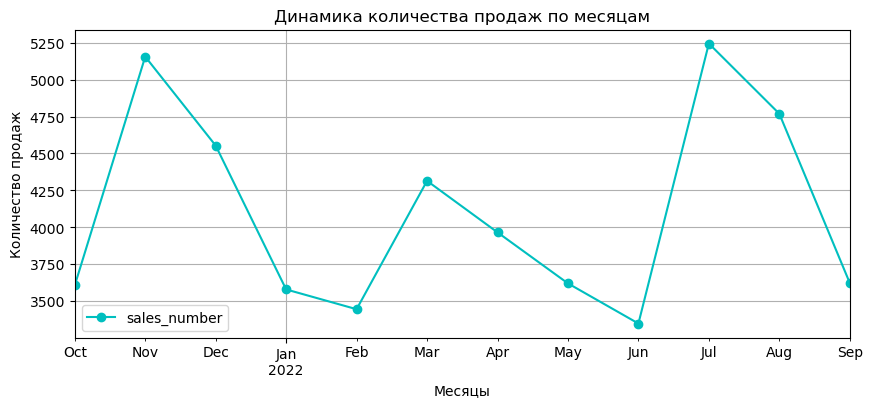

In [53]:
mon_report.plot(x='year_month',
                y='sales_number',
                style='o-',
                color='c',
                grid=True,
                figsize=(10, 4),
                title='Динамика количества продаж по месяцам',
                ylabel='Количество продаж',
                xlabel='Месяцы')

Судя по графикам больше всего продаж по количеству было в июле, ноябре, августе, декабре и марте (по убыванию).\
Меньше всего продаж по количеству было в июне, феврале, январе и сентябре, октябре (по возрастанию).

По сумме продаж больше всего получилось в июле, авусте, апреле, ноябре, дкабре и марте (по убыванию).\
Меньше всего по сумме продаж в январе, феврале, октябре.

Сезонность\
Получается, по сумме продаж самый сезон - это лето (июль-август), как раз период отпусков.\
По количеству продаж сезон также летом (июль-август) и осенью (ноябрь-декабрь). Однако в ноябре-декабре сумма продаж не полностью коррелирует с количеством.

Осенью и зимой у нас похожие ситуации: в двух из трех месяцах очень низкие продажи как по количеству, так и по сумме. **Проверим гипотезу об отличие выручки зимой и осенью.**

***Нулевая гипотеза:*** Выручка от продаж осенью НЕ отличается от выручки от продаж зимой. Выручка осенью = выручке зимой\
***Альтернативная гипотеза:*** Выручка от продаж осенью отличается от выручки от продаж зимой. Выручка осенью != выручке зимой


<div class="alert alert-block alert-danger">
Комментарий от преподавателя:
    
Здесь предлагаю сделать категоризацию по времени года, далее сделать группировку по времени года и посмотреть корреляцию.
Так же все это можно повторить по месяцам

In [54]:
#исправление
new_dfo['month'] = pd.to_datetime(new_dfo['issue_date']).dt.month

In [55]:
#категоризация по времени года в столбце season
def season_def(date_ym):
    if date_ym == 9 or date_ym == 10 or date_ym == 11:
        return 'autumn'
    if date_ym == 12 or date_ym == 1 or date_ym == 2:
        return 'winter'
    if date_ym == 3 or date_ym == 4 or date_ym == 5:
        return 'spring'
    if date_ym == 6 or date_ym == 7 or date_ym == 8:
        return 'summer'


new_dfo['season'] = new_dfo['month'].apply(season_def)

In [56]:
new_dfo.groupby('season')['revenue_amount'].sum().reset_index(name='revenue_sum')

,season,revenue_sum
0,autumn,4746600
1,spring,5529040
2,summer,6653310
3,winter,4397220


In [57]:
#сумма и количество продаж по временам года
seas = new_dfo.groupby('season')['revenue_amount'].agg(['sum', 'count', 'mean']).reset_index()
seas

,season,sum,count,mean
0,autumn,4746600,12384,383.284884
1,spring,5529040,11898,464.703311
2,summer,6653310,13361,497.964973
3,winter,4397220,11575,379.889417


In [58]:
#корреляция
seas.corr()

,sum,count,mean
sum,1.000000,0.834909,0.961958
count,0.834909,1.000000,0.654704
mean,0.961958,0.654704,1.000000


In [59]:
#по месяцам сделано выше

Проверка гопотезы об отличие выручки зимой и осенью.

***Нулевая гипотеза:*** Выручка от продаж осенью НЕ отличается от выручки от продаж зимой. Выручка осенью = выручке зимой\
***Альтернативная гипотеза:*** Выручка от продаж осенью отличается от выручки от продаж зимой. Выручка осенью != выручке зимой

In [60]:
#датафрейм только осенью
autumn_dfo = new_dfo[new_dfo['season'] == 'autumn']
a_rev_list = autumn_dfo['revenue_amount'].tolist()

#датафрейм только зимой
winter_dfo = new_dfo[new_dfo['season'] == 'winter']
w_rev_list = winter_dfo['revenue_amount'].tolist()

In [61]:
#посмотрим средние 
print(np.mean(a_rev_list))
print(np.mean(w_rev_list))

383.2848837209302
379.8894168466523


***Проверим распределение на нормальность***

(array([ 910., 4387., 3392., 2190.,  923.,  398.,  104.,   44.,   24.,
          12.]),
 array([  20.,  166.,  312.,  458.,  604.,  750.,  896., 1042., 1188.,
        1334., 1480.]),
 <BarContainer object of 10 artists>)

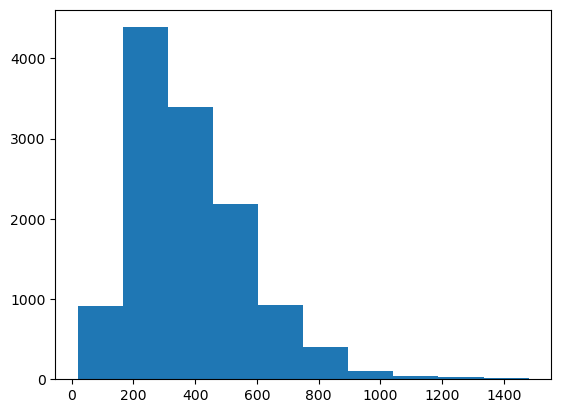

In [62]:
#для осени
plt.hist(a_rev_list)

<AxesSubplot:ylabel='Density'>

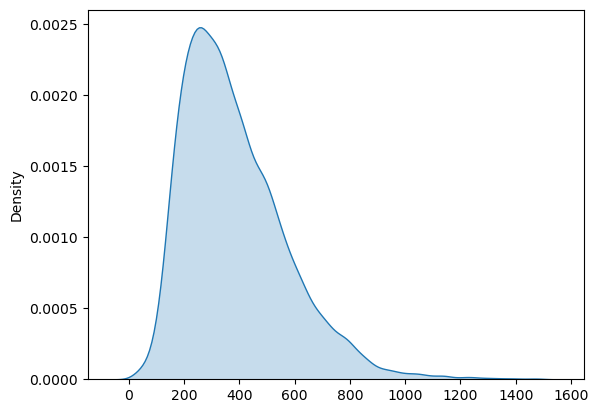

In [63]:
sns.kdeplot(a_rev_list, fill=True)

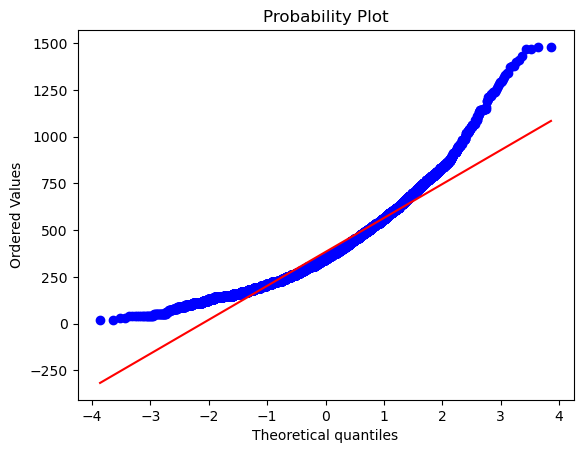

In [64]:
st.probplot(a_rev_list, dist='norm', plot=plt)
plt.show()

(array([ 946., 4076., 3341., 1904.,  831.,  318.,   92.,   40.,   19.,
           8.]),
 array([  30.,  174.,  318.,  462.,  606.,  750.,  894., 1038., 1182.,
        1326., 1470.]),
 <BarContainer object of 10 artists>)

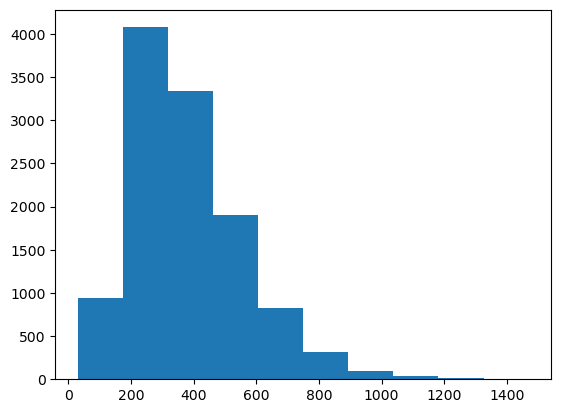

In [65]:
#для зимы
plt.hist(w_rev_list)

<AxesSubplot:ylabel='Density'>

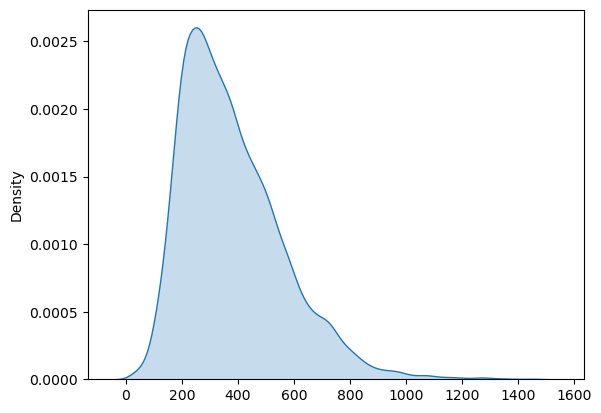

In [66]:
sns.kdeplot(w_rev_list, fill=True)

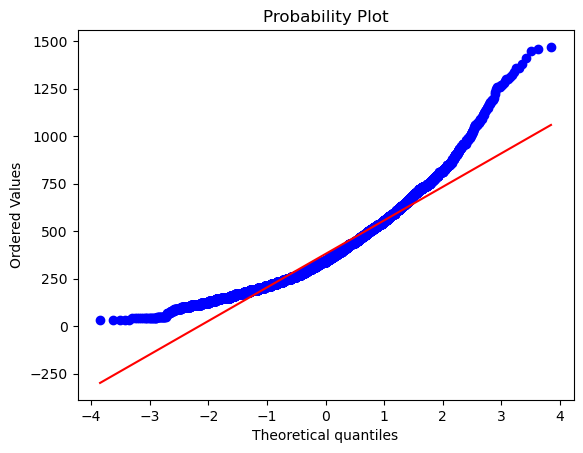

In [67]:
st.probplot(w_rev_list, dist='norm', plot=plt)
plt.show()

**Вывод:** обе выборки не имеют нормального распределения. В связи с этим нет возможности применить t-test. Для проверки гипотезы проведем непараметрический тест Уилкоксона-Манна-Уитни

In [68]:
#проверка гипотез (тест Уилкоксона-Манна-Уитни)
alpha = 0.05

results = st.mannwhitneyu(a_rev_list, w_rev_list)

print('p-value', results.pvalue)

if results.pvalue < alpha:
    print('Следует отвергнуть нулевую гипотезу')
else:
    print('Не удалось отвергнуть нулевую гипотезу')

p-value 0.3767023956775051
Не удалось отвергнуть нулевую гипотезу


Таким образом, нет достаточных оснований, чтобы утверждать, что выручка от продаж осенью отличается от выручки от продаж зимой. Значит, выручки осенью и зимой равны. 

### Покупка билетов в разное время

In [70]:
#создаем новый столбец с разницей между днем покупки и днем вылета
new_dfo['delta_days'] = (new_dfo['flight_date_loc'] - new_dfo['issue_date']).dt.days
new_dfo

,issue_date,flight_date_loc,pax_type,revenue_amount,orig_city_code,dest_city_code,route_flight_type,ffp_flag,sale_type,year_month,month,season,delta_days
0,2021-10-01,2021-10-04,AD,370,OVB,LED,DOF,1,ONLINE,2021-10,10,autumn,3
1,2021-10-01,2021-10-04,AD,390,KUF,MOW,DOF,1,ONLINE,2021-10,10,autumn,3
2,2021-10-01,2021-10-02,AD,840,OVB,VVO,DOF,1,OFFLINE,2021-10,10,autumn,1
3,2021-10-01,2021-10-31,AD,330,UUD,OVB,DOF,1,ONLINE,2021-10,10,autumn,30
4,2021-10-01,2021-10-10,AD,340,VOZ,MOW,DOF,0,OFFLINE,2021-10,10,autumn,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...
49213,2022-09-30,2022-10-02,AD,670,IKT,MOW,DOF,0,OFFLINE,2022-09,9,autumn,2
49214,2022-09-30,2022-10-03,AD,350,KUF,MOW,DOF,0,OFFLINE,2022-09,9,autumn,3
49215,2022-09-30,2022-10-04,AD,310,SVX,MOW,DOF,0,OFFLINE,2022-09,9,autumn,4
49216,2022-09-30,2022-10-02,AD,480,ABA,OVB,DOF,0,OFFLINE,2022-09,9,autumn,2


<AxesSubplot:ylabel='Frequency'>

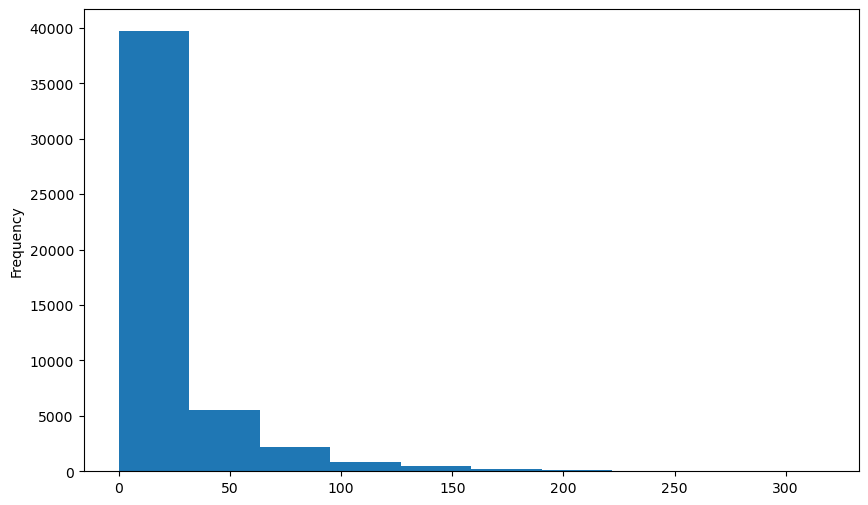

In [71]:
new_dfo['delta_days'].plot(kind='hist', figsize=(10, 6))

In [72]:
new_dfo['delta_days'].describe()

count    49218.000000
mean        20.953330
std         30.845906
min          0.000000
25%          3.000000
50%          9.000000
75%         25.000000
max        317.000000
Name: delta_days, dtype: float64

Нам нужно принять решение о том, как разделить клиентов на три группы.\
Исследовав значения, мы видим, что чаще всего люди покупают билет за 9 дней (медиана). Есть те, кто покупает билеты в день вылета (минимальное = 0), также есть выбросы (максимальное = 317); всего клиентов, которые купили билеты очень заранее, за 100 дней, равно 1592 человека.\
Однако 75% всех клиентов покупают билеты не позднее 25 дней.

Получается, лучше разбить всех клиентов на четыре группы соответсвенно по квартилям - 25% (не позднее 3 дней), 50% (не позднее 9 дней), 75% (не позднее 25 дней) и все остальные (очень заранее - больше, чем за 25 дней).

***Расшифровка категорий:***

lastmom (last moment) - не позднее 3 дней\
less (less in advance) - не позднее 9 дней\
more (more in advance) - не позднее 25 дней\
toomuch (too much in advance) - все остальные (очень заранее - больше, чем за 25 дней)

In [73]:
#разбили на категории
bin_labels = ['lastmom', 'less', 'more', 'toomuch']

new_dfo['groups_inadv'] = pd.qcut(new_dfo['delta_days'],
                                  q=[0, .25, .5, .75, 1],
                                  labels=bin_labels)
new_dfo

,issue_date,flight_date_loc,pax_type,revenue_amount,orig_city_code,dest_city_code,route_flight_type,ffp_flag,sale_type,year_month,month,season,delta_days,groups_inadv
0,2021-10-01,2021-10-04,AD,370,OVB,LED,DOF,1,ONLINE,2021-10,10,autumn,3,lastmom
1,2021-10-01,2021-10-04,AD,390,KUF,MOW,DOF,1,ONLINE,2021-10,10,autumn,3,lastmom
2,2021-10-01,2021-10-02,AD,840,OVB,VVO,DOF,1,OFFLINE,2021-10,10,autumn,1,lastmom
3,2021-10-01,2021-10-31,AD,330,UUD,OVB,DOF,1,ONLINE,2021-10,10,autumn,30,toomuch
4,2021-10-01,2021-10-10,AD,340,VOZ,MOW,DOF,0,OFFLINE,2021-10,10,autumn,9,less
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49213,2022-09-30,2022-10-02,AD,670,IKT,MOW,DOF,0,OFFLINE,2022-09,9,autumn,2,lastmom
49214,2022-09-30,2022-10-03,AD,350,KUF,MOW,DOF,0,OFFLINE,2022-09,9,autumn,3,lastmom
49215,2022-09-30,2022-10-04,AD,310,SVX,MOW,DOF,0,OFFLINE,2022-09,9,autumn,4,less
49216,2022-09-30,2022-10-02,AD,480,ABA,OVB,DOF,0,OFFLINE,2022-09,9,autumn,2,lastmom


<div class="alert alert-block alert-success">
Это отличное решение по разделению на группы.

Теперь для проверки гипотезы будем считать, что lastmom - это "в последний момент", а less + more + toomuch - это "заранее". Я включаю less в группу "заранее" из соображений, что 4-9 дней до вылета - это не последний момент. Так, получается, сравнивать мы будем две группы.

**?** Ничего страшного, что я не стала исключать выбросы из toomuch? И что у нас выборки получаются очень разного размера???


Проверка гипотезы\
***Нулевая гипотеза:*** выручка от продажи билетов первой группе ("в последний момент") НЕ отличается от выручки от продажи билетов второй группе ("заранее"). Выручка "в последний момент" = Выручка "заранее"\
***Альтернативная гипотеза:*** выручка от продажи билетов первой группе ("в последний момент") отличается от выручки от продажи билетов второй группе ("заранее"). Выручка "в последний момент" != Выручка "заранее"

In [74]:
#датафрейм только "в последний момент"
lastmom_dfo = new_dfo[new_dfo['groups_inadv'] == 'lastmom']

#значения выручки "в последний момент" в виде списка
lastmom_revenue_list = lastmom_dfo['revenue_amount'].tolist()

In [75]:
#датафрейм только "заранее"
inadvance_dfo = new_dfo[(new_dfo['groups_inadv'] == 'less') | (new_dfo['groups_inadv'] == 'more') | (new_dfo['groups_inadv'] == 'toomuch')]

#значения выручки "заранее" в виде списка
inadvance_revenue_list = inadvance_dfo['revenue_amount'].tolist()

In [76]:
print(np.mean(lastmom_revenue_list))
print(np.mean(inadvance_revenue_list))

420.8804980595084
437.4686567164179


Для принятия решения о проведении теста для проверки гипотезы сначала ***проверим распределение на нормальность***

(array([ 488., 3880., 3766., 2174., 1237.,  504.,  183.,   73.,   42.,
          21.]),
 array([  20.,  167.,  314.,  461.,  608.,  755.,  902., 1049., 1196.,
        1343., 1490.]),
 <BarContainer object of 10 artists>)

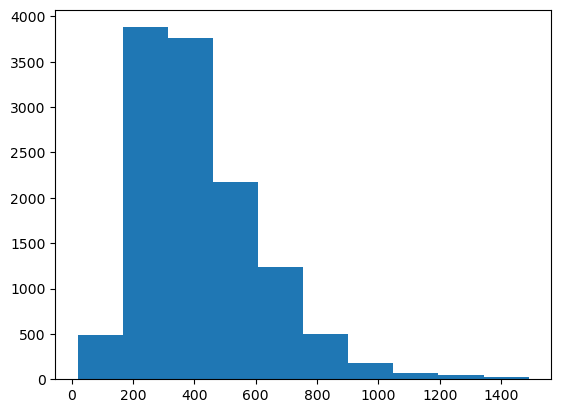

In [77]:
#для группы "в последний момент"
plt.hist(lastmom_revenue_list)

<AxesSubplot:ylabel='Density'>

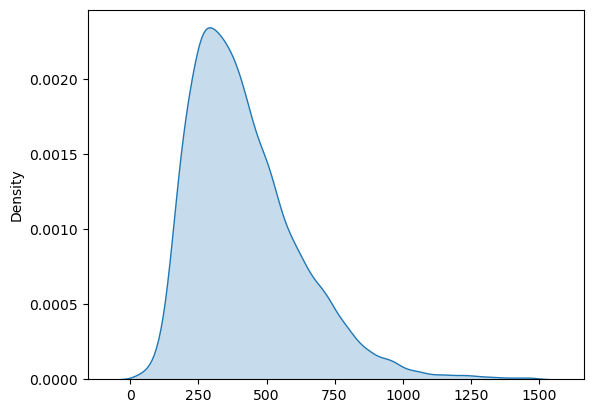

In [78]:
sns.kdeplot(lastmom_revenue_list, fill=True)

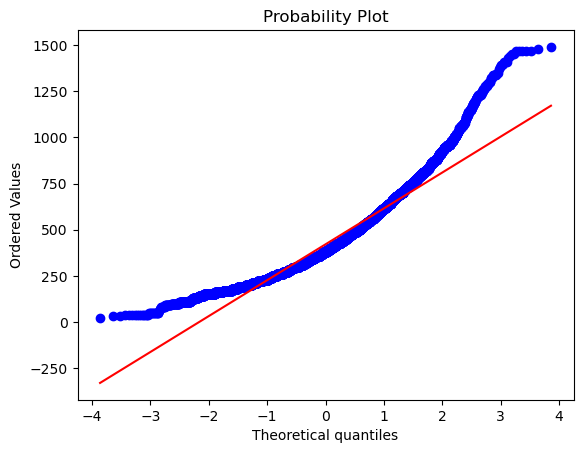

In [79]:
st.probplot(lastmom_revenue_list, dist='norm', plot=plt)
plt.show()

(array([ 1275.,  8849., 11454.,  8591.,  4057.,  1749.,   591.,   185.,
           67.,    32.]),
 array([  10.,  158.,  306.,  454.,  602.,  750.,  898., 1046., 1194.,
        1342., 1490.]),
 <BarContainer object of 10 artists>)

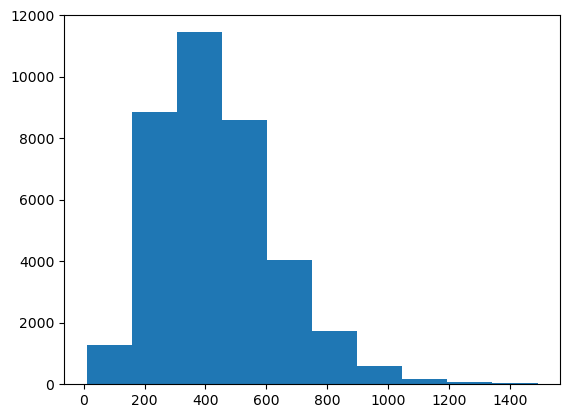

In [80]:
#для группы "заранее"
plt.hist(inadvance_revenue_list)

<AxesSubplot:ylabel='Density'>

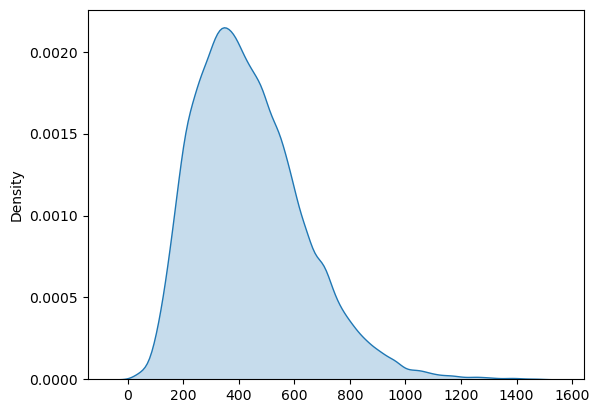

In [81]:
sns.kdeplot(inadvance_revenue_list, fill=True)

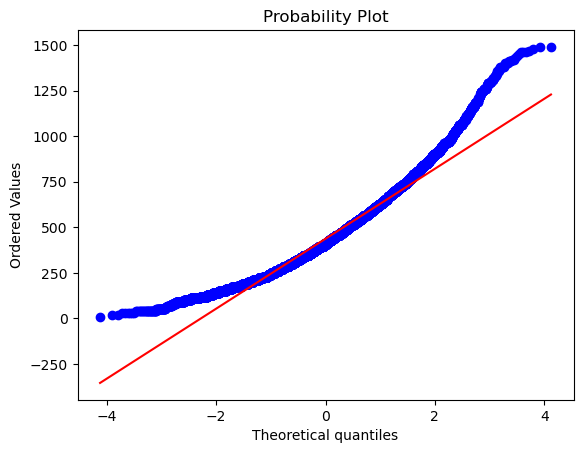

In [82]:
st.probplot(inadvance_revenue_list, dist='norm', plot=plt)
plt.show()

**Вывод:** обе выборки не имеют нормального распределения. В связи с этим нет возможности применить t-test. Для проверки гипотезы проведем непараметрический тест Уилкоксона-Манна-Уитни

In [83]:
#проверка гипотез (тест Уилкоксона-Манна-Уитни)
alpha = 0.05

results = st.mannwhitneyu(lastmom_revenue_list, inadvance_revenue_list)

print('p-value', results.pvalue)

if results.pvalue < alpha:
    print('Следует отвергнуть нулевую гипотезу')
else:
    print('Не удалось отвергнуть нулевую гипотезу')

p-value 4.391708628518943e-29
Следует отвергнуть нулевую гипотезу


**Вывод:**\
Таким образом, следует отклонить нулевую гипотезу о равенстве выручки от продажи билетов первой группе ("в последний момент") и второй группе ("заранее"). Выручка от продажи билетов в этих двух группах отличается.

<AxesSubplot:xlabel='groups_inadv', ylabel='revenue_amount'>

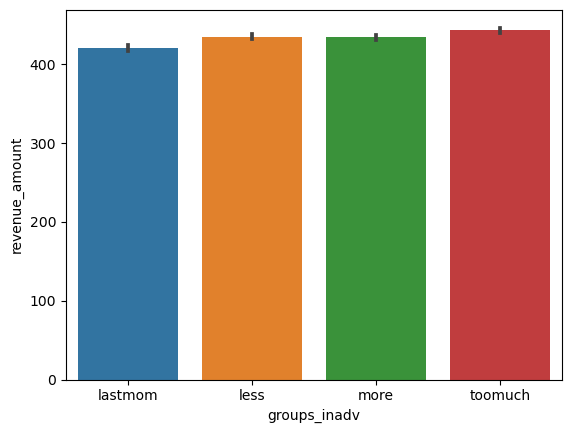

In [85]:
sns.barplot(x="groups_inadv", y="revenue_amount", data=new_dfo)

<div class="alert alert-block alert-warning">
Комментарий от преподавателя:
    
Постройте дополнительно barplot с доверительным интервалом. Сравните сравните средние значение и соотесите с результатом теста, тогда и выводы сформируются.
pvalue у Вас 6*10в степени -16 т.е оооочень мальнький

<AxesSubplot:>

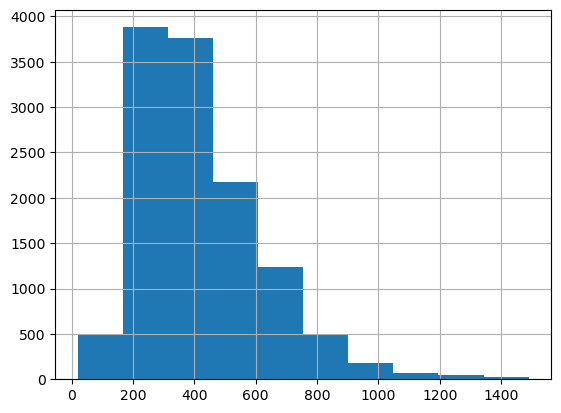

In [86]:
#хочу посмотреть выручку и ее распределение в 1 и 2 группе
#построим гистограммы
lastmom_dfo['revenue_amount'].hist()

<AxesSubplot:>

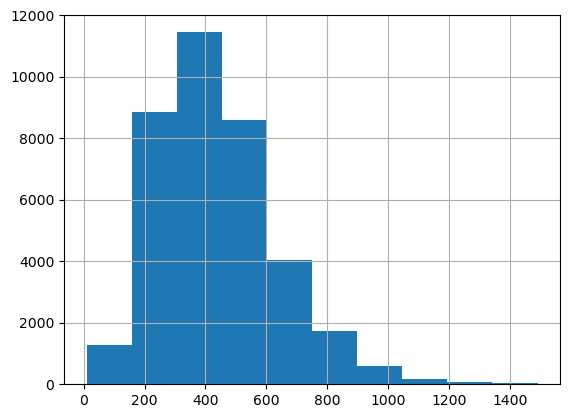

In [87]:
inadvance_dfo['revenue_amount'].hist()

И в первой, и во второй группе ("в последний момент" и "заранее") выручка, полученная от продажи одному клиенту чаще всего находится в диапазоне примерно от 200 до 600 условных единиц. Причем, в группе "в последний момент" все же выручка от 400 до 600 встречается реже, чем во второй группе.

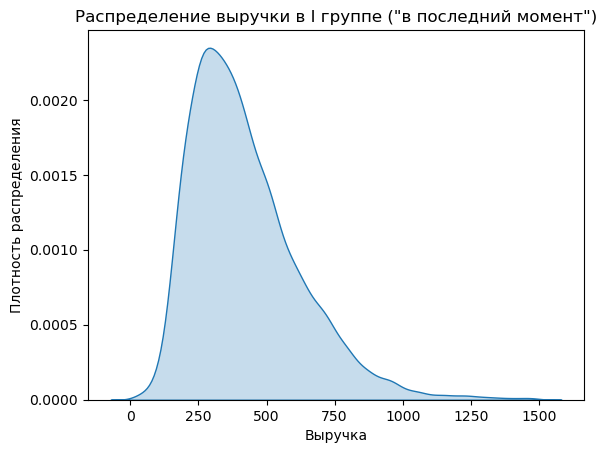

In [88]:
# и построим графики функции плотности
sns.kdeplot(lastmom_revenue_list, fill=True)
 
# добавим подписи
plt.xlabel('Выручка')
plt.ylabel('Плотность распределения')
plt.title('Распределение выручки в I группе ("в последний момент")')
 
plt.show()

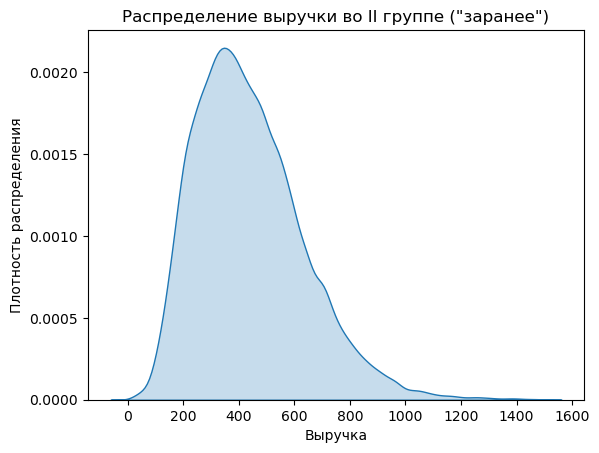

In [89]:
sns.kdeplot(inadvance_revenue_list, fill=True)
 
# добавим подписи
plt.xlabel('Выручка')
plt.ylabel('Плотность распределения')
plt.title('Распределение выручки во II группе ("заранее")')
 
plt.show()

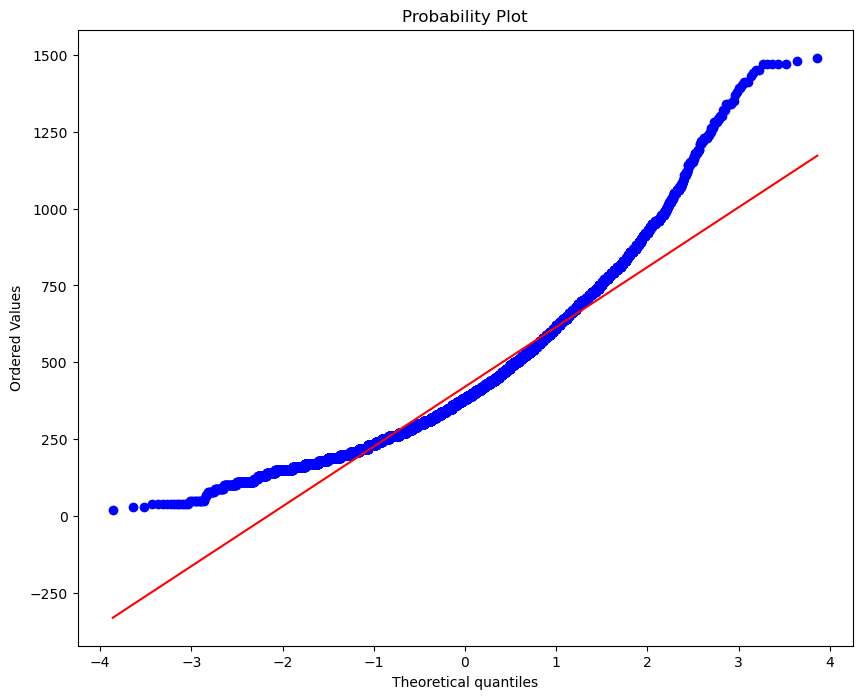

In [90]:
#Q-Q plot для выручки в I группе ("в последний момент")
plt.figure(figsize=(10,8))
st.probplot(lastmom_revenue_list, dist='norm', plot=plt)
plt.show()

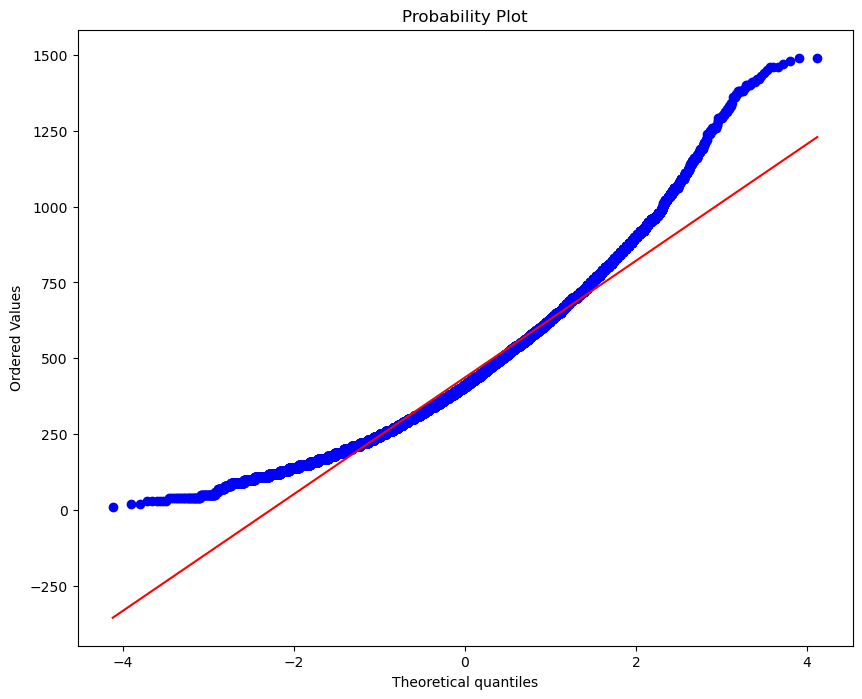

In [91]:
#Q-Q plot для выручки во II группе ("заранее")
plt.figure(figsize=(10,8))
st.probplot(inadvance_revenue_list, dist='norm', plot=plt)
plt.show()

***Судя по всем этим графикам, наше распределение как в первой, так и во второй группе, НЕ является нормальным. Значит, возможно, именно это оказало влияние на корректность t-теста.***

### Определим популярные направления

In [93]:
extra_df = pd.read_csv('https://raw.githubusercontent.com/jpatokal/openflights/master/data/airports.dat', 
                       names = ['Airport_name', 'Location', 'Country', 'IATA_Code', 'ICAO_Code', 'Latitude', 'Longitude', 'Altitude', 'Timezone', 'DST', 'Timezone Region', 'Type', 'Source'],
                       header=None)

In [94]:
extra_df.columns = extra_df.columns.str.lower()

In [95]:
extra_df.head()

,airport_name,location,country,iata_code,icao_code,latitude,longitude,altitude,timezone,dst,timezone region,type,source
1,Goroka Airport,Goroka,Papua New Guinea,GKA,AYGA,-6.081690,145.391998,5282,10,U,Pacific/Port_Moresby,airport,OurAirports
2,Madang Airport,Madang,Papua New Guinea,MAG,AYMD,-5.207080,145.789001,20,10,U,Pacific/Port_Moresby,airport,OurAirports
3,Mount Hagen Kagamuga Airport,Mount Hagen,Papua New Guinea,HGU,AYMH,-5.826790,144.296005,5388,10,U,Pacific/Port_Moresby,airport,OurAirports
4,Nadzab Airport,Nadzab,Papua New Guinea,LAE,AYNZ,-6.569803,146.725977,239,10,U,Pacific/Port_Moresby,airport,OurAirports
5,Port Moresby Jacksons International Airport,Port Moresby,Papua New Guinea,POM,AYPY,-9.443380,147.220001,146,10,U,Pacific/Port_Moresby,airport,OurAirports


iata_code соотносится с dest_city_code и orig_city_code => можно расшифровать по этому полю

In [96]:
df_code_city = extra_df[['iata_code','location']]
df_code_city

,iata_code,location
1,GKA,Goroka
2,MAG,Madang
3,HGU,Mount Hagen
4,LAE,Nadzab
5,POM,Port Moresby
...,...,...
14106,\N,Belaya
14107,\N,Ulan Ude
14108,\N,Novgorod
14109,CPO,Copiapo


In [97]:
df_code_city.info() #в location есть пропуски

<class 'pandas.core.frame.DataFrame'>
Int64Index: 7698 entries, 1 to 14110
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   iata_code  7698 non-null   object
 1   location   7649 non-null   object
dtypes: object(2)
memory usage: 180.4+ KB


In [98]:
new_dfo = new_dfo.merge(df_code_city, how='left', left_on='orig_city_code', right_on='iata_code')

In [99]:
new_dfo = new_dfo.merge(df_code_city, how='left', left_on='dest_city_code', right_on='iata_code')

orig_city_code записалось в location_x\
dest_city_code записалось в location_y

In [ ]:
#прошу прощения за такую реализацию, никак иначе у меня не получилось

In [100]:
new_dfo

,issue_date,flight_date_loc,pax_type,revenue_amount,orig_city_code,dest_city_code,route_flight_type,ffp_flag,sale_type,year_month,month,season,delta_days,groups_inadv,iata_code_x,location_x,iata_code_y,location_y
0,2021-10-01,2021-10-04,AD,370,OVB,LED,DOF,1,ONLINE,2021-10,10,autumn,3,lastmom,OVB,Novosibirsk,LED,St. Petersburg
1,2021-10-01,2021-10-04,AD,390,KUF,MOW,DOF,1,ONLINE,2021-10,10,autumn,3,lastmom,KUF,Samara,NaN,NaN
2,2021-10-01,2021-10-02,AD,840,OVB,VVO,DOF,1,OFFLINE,2021-10,10,autumn,1,lastmom,OVB,Novosibirsk,VVO,Vladivostok
3,2021-10-01,2021-10-31,AD,330,UUD,OVB,DOF,1,ONLINE,2021-10,10,autumn,30,toomuch,UUD,Ulan-ude,OVB,Novosibirsk
4,2021-10-01,2021-10-10,AD,340,VOZ,MOW,DOF,0,OFFLINE,2021-10,10,autumn,9,less,VOZ,Voronezh,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49213,2022-09-30,2022-10-02,AD,670,IKT,MOW,DOF,0,OFFLINE,2022-09,9,autumn,2,lastmom,IKT,Irkutsk,NaN,NaN
49214,2022-09-30,2022-10-03,AD,350,KUF,MOW,DOF,0,OFFLINE,2022-09,9,autumn,3,lastmom,KUF,Samara,NaN,NaN
49215,2022-09-30,2022-10-04,AD,310,SVX,MOW,DOF,0,OFFLINE,2022-09,9,autumn,4,less,SVX,Yekaterinburg,NaN,NaN
49216,2022-09-30,2022-10-02,AD,480,ABA,OVB,DOF,0,OFFLINE,2022-09,9,autumn,2,lastmom,ABA,Abakan,OVB,Novosibirsk


In [118]:
new_dfo.isna().sum()

issue_date               0
flight_date_loc          0
pax_type                 0
revenue_amount           0
orig_city_code           0
dest_city_code           0
route_flight_type        0
ffp_flag                 0
sale_type                0
year_month               0
month                    0
season                   0
delta_days               0
groups_inadv             0
iata_code_x          16129
location_x           16129
iata_code_y          16248
location_y           16248
pair_code                0
dtype: int64

заполнились не все города

In [114]:
new_dfo['location_x'].isnull().sum()

16129

In [115]:
new_dfo[new_dfo['orig_city_code'] == 'MOW'] #не заполнилась москва 

,issue_date,flight_date_loc,pax_type,revenue_amount,orig_city_code,dest_city_code,route_flight_type,ffp_flag,sale_type,year_month,month,season,delta_days,groups_inadv,iata_code_x,location_x,iata_code_y,location_y,pair_code
5,2021-10-01,2021-10-02,AD,280,MOW,LED,DOF,0,OFFLINE,2021-10,10,autumn,1,lastmom,NaN,NaN,LED,St. Petersburg,MOWLED
6,2021-10-01,2021-10-03,AD,240,MOW,MRV,DOF,0,OFFLINE,2021-10,10,autumn,2,lastmom,NaN,NaN,MRV,Mineralnye Vody,MOWMRV
8,2021-10-01,2021-10-03,AD,300,MOW,SIP,DOF,0,ONLINE,2021-10,10,autumn,2,lastmom,NaN,NaN,SIP,Simferopol,MOWSIP
9,2021-10-01,2021-10-04,AD,460,MOW,AYT,INF,0,OFFLINE,2021-10,10,autumn,3,lastmom,NaN,NaN,AYT,Antalya,MOWAYT
14,2021-10-01,2021-10-10,AD,250,MOW,MMK,DOF,0,OFFLINE,2021-10,10,autumn,9,less,NaN,NaN,MMK,Murmansk,MOWMMK
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49207,2022-09-30,2022-10-01,AD,660,MOW,OSS,INF,0,ONLINE,2022-09,9,autumn,1,lastmom,NaN,NaN,OSS,Osh,MOWOSS
49209,2022-09-30,2022-10-03,AD,150,MOW,AYT,INF,0,OFFLINE,2022-09,9,autumn,3,lastmom,NaN,NaN,AYT,Antalya,MOWAYT
49210,2022-09-30,2022-10-02,AD,660,MOW,OSS,INF,0,OFFLINE,2022-09,9,autumn,2,lastmom,NaN,NaN,OSS,Osh,MOWOSS
49211,2022-09-30,2022-10-03,AD,1470,MOW,KEJ,DOF,0,OFFLINE,2022-09,9,autumn,3,lastmom,NaN,NaN,KEJ,Kemorovo,MOWKEJ


по orig_city_code 16129 пропусков, из них 15854 не заполнилась Москва

остальные 275 пропусков приходятся на следующие коды
BAK
PAR
SEL
GRV\
заполняю их на unknown

In [129]:
unkn = new_dfo[(new_dfo['location_x'].isnull() == True) & (new_dfo['orig_city_code'] != 'MOW')]

In [130]:
unkn['location_x'] = unkn['location_x'].fillna('unknown')
new_dfo[(new_dfo['location_x'].isnull() == True) & (new_dfo['orig_city_code'] != 'MOW')] = unkn

C:\Users\Liza\AppData\Local\Temp\ipykernel_13428\4235898870.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  unkn['location_x'] = unkn['location_x'].fillna('unknown')


In [134]:
new_dfo['location_x'] = new_dfo['location_x'].fillna('Moscow') #остальные пропуски заполнили москвой

In [ ]:
#делаем то же самое по location_y и dest_city_code

In [136]:
new_dfo[new_dfo['dest_city_code'] == 'MOW'] #16006 из 16248 пропусков это москва

,issue_date,flight_date_loc,pax_type,revenue_amount,orig_city_code,dest_city_code,route_flight_type,ffp_flag,sale_type,year_month,month,season,delta_days,groups_inadv,iata_code_x,location_x,iata_code_y,location_y,pair_code
1,2021-10-01,2021-10-04,AD,390,KUF,MOW,DOF,1,ONLINE,2021-10,10,autumn,3,lastmom,KUF,Samara,NaN,NaN,KUFMOW
4,2021-10-01,2021-10-10,AD,340,VOZ,MOW,DOF,0,OFFLINE,2021-10,10,autumn,9,less,VOZ,Voronezh,NaN,NaN,VOZMOW
11,2021-10-01,2021-10-12,AD,140,LED,MOW,DOF,0,ONLINE,2021-10,10,autumn,11,more,LED,St. Petersburg,NaN,NaN,LEDMOW
15,2021-10-01,2021-10-09,AD,330,KRR,MOW,DOF,0,OFFLINE,2021-10,10,autumn,8,less,KRR,Krasnodar,NaN,NaN,KRRMOW
17,2021-10-01,2021-10-30,CHD,180,GDZ,MOW,DOF,0,ONLINE,2021-10,10,autumn,29,toomuch,GDZ,Gelendzhik,NaN,NaN,GDZMOW
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49199,2022-09-30,2022-10-04,AD,220,PEE,MOW,DOF,0,OFFLINE,2022-09,9,autumn,4,less,PEE,Perm,NaN,NaN,PEEMOW
49202,2022-09-30,2022-10-04,AD,330,OVB,MOW,DOF,1,ONLINE,2022-09,9,autumn,4,less,OVB,Novosibirsk,NaN,NaN,OVBMOW
49213,2022-09-30,2022-10-02,AD,670,IKT,MOW,DOF,0,OFFLINE,2022-09,9,autumn,2,lastmom,IKT,Irkutsk,NaN,NaN,IKTMOW
49214,2022-09-30,2022-10-03,AD,350,KUF,MOW,DOF,0,OFFLINE,2022-09,9,autumn,3,lastmom,KUF,Samara,NaN,NaN,KUFMOW


In [138]:
unkn1 = new_dfo[(new_dfo['location_y'].isnull() == True) & (new_dfo['dest_city_code'] != 'MOW')] 
#остальное 242 пропуска те же самые
#так же заполню их на unknown

In [139]:
unkn1['location_y'] = unkn1['location_y'].fillna('unknown')
new_dfo[(new_dfo['location_y'].isnull() == True) & (new_dfo['dest_city_code'] != 'MOW')] = unkn1

C:\Users\Liza\AppData\Local\Temp\ipykernel_13428\1801142841.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  unkn1['location_y'] = unkn1['location_y'].fillna('unknown')


In [140]:
new_dfo['location_y'] = new_dfo['location_y'].fillna('Moscow')

In [141]:
new_dfo.isna().sum()

issue_date               0
flight_date_loc          0
pax_type                 0
revenue_amount           0
orig_city_code           0
dest_city_code           0
route_flight_type        0
ffp_flag                 0
sale_type                0
year_month               0
month                    0
season                   0
delta_days               0
groups_inadv             0
iata_code_x          16129
location_x               0
iata_code_y          16248
location_y               0
pair_code                0
dtype: int64

In [ ]:
#интересующие пропуски заполнены

In [142]:
#новый столбец город-город 
new_dfo['city_city'] = new_dfo['location_x'] + new_dfo['location_y']
new_dfo.head()

,issue_date,flight_date_loc,pax_type,revenue_amount,orig_city_code,dest_city_code,route_flight_type,ffp_flag,sale_type,year_month,month,season,delta_days,groups_inadv,iata_code_x,location_x,iata_code_y,location_y,pair_code,city_city
0,2021-10-01,2021-10-04,AD,370,OVB,LED,DOF,1,ONLINE,2021-10,10,autumn,3,lastmom,OVB,Novosibirsk,LED,St. Petersburg,OVBLED,NovosibirskSt. Petersburg
1,2021-10-01,2021-10-04,AD,390,KUF,MOW,DOF,1,ONLINE,2021-10,10,autumn,3,lastmom,KUF,Samara,NaN,Moscow,KUFMOW,SamaraMoscow
2,2021-10-01,2021-10-02,AD,840,OVB,VVO,DOF,1,OFFLINE,2021-10,10,autumn,1,lastmom,OVB,Novosibirsk,VVO,Vladivostok,OVBVVO,NovosibirskVladivostok
3,2021-10-01,2021-10-31,AD,330,UUD,OVB,DOF,1,ONLINE,2021-10,10,autumn,30,toomuch,UUD,Ulan-ude,OVB,Novosibirsk,UUDOVB,Ulan-udeNovosibirsk
4,2021-10-01,2021-10-10,AD,340,VOZ,MOW,DOF,0,OFFLINE,2021-10,10,autumn,9,less,VOZ,Voronezh,NaN,Moscow,VOZMOW,VoronezhMoscow


In [144]:
new_dfo['pair_code'] = new_dfo['orig_city_code'] + new_dfo['dest_city_code']

In [146]:
#топ 10 популярных направлений по всему датасету по городам
new_dfo.city_city.value_counts().to_frame().head(10)

,city_city
SochiMoscow,1336
MoscowSochi,1306
St. PetersburgMoscow,1212
MoscowSt. Petersburg,1192
NovosibirskMoscow,970
MoscowNovosibirsk,947
KazanMoscow,760
MoscowKazan,758
MoscowUfa,708
NovosibirskSochi,695


In [145]:
#топ 10 популярных направлений по всему датасету по кодам
#new_dfo.pair_code.value_counts().to_frame().head(10)

In [147]:
intern_f = new_dfo[new_dfo['route_flight_type'] == 'INF']
domest_f = new_dfo[new_dfo['route_flight_type'] == 'DOF']

***Отчет ТОП-10 направлений среди международных перелетов***

In [148]:
#топ 10 популярных направлений для МВЛ (международные перелеты)
intern_f.city_city.value_counts().to_frame().head(10) #я оставила так, потому что вид более презентабельный, чем через reset_index

,city_city
MoscowOsh,153
KhudzhandMoscow,146
OshMoscow,136
MoscowKhudzhand,130
NovosibirskOsh,121
NovosibirskBishkek,120
OshNovosibirsk,116
KhudzhandNovosibirsk,116
MoscowAntalya,103
BishkekNovosibirsk,102


<AxesSubplot:title={'center':'ТОП-10 направлений по международным перелетам'}, xlabel='Направления'>

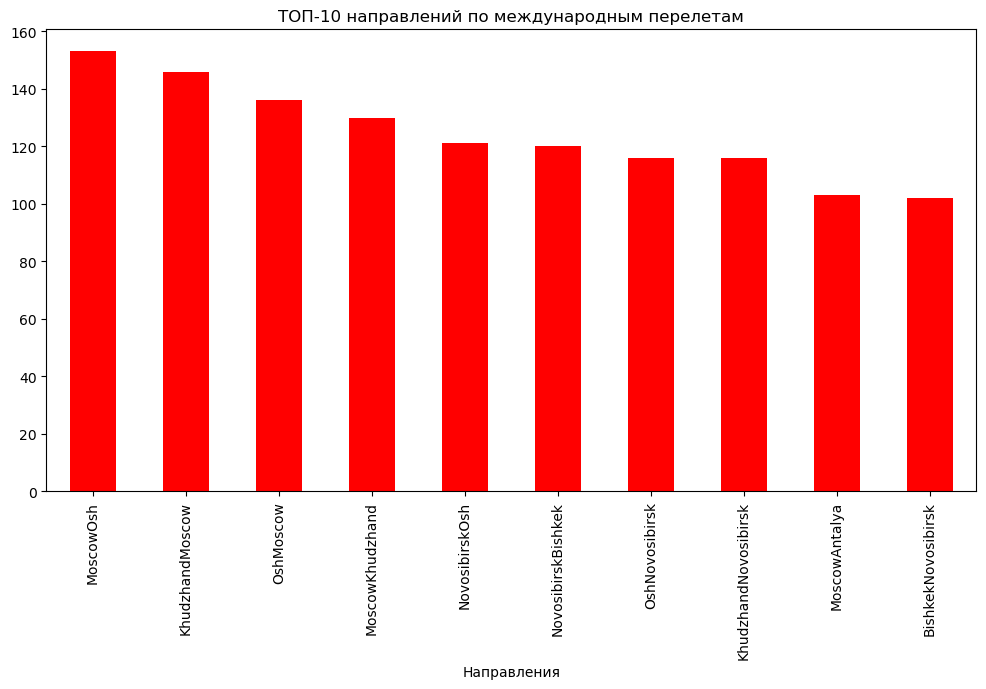

In [169]:
i = intern_f.city_city.value_counts().reset_index()
i[:10].plot(kind='bar',
        x='index',
        y='city_city',
        figsize=(12, 6),
        title='ТОП-10 направлений по международным перелетам',
        xlabel='Направления',
        legend=False,
        color='r')

***Отчет ТОП-10 направлений среди внутренних перелетов***

In [171]:
#топ 10 популярных направлений по коду для ВМЛ (внутренние перелеты)
domest_f.city_city.value_counts().to_frame().head(10) 

,city_city
SochiMoscow,1336
MoscowSochi,1306
St. PetersburgMoscow,1212
MoscowSt. Petersburg,1192
NovosibirskMoscow,970
MoscowNovosibirsk,947
KazanMoscow,760
MoscowKazan,758
MoscowUfa,708
NovosibirskSochi,695


<AxesSubplot:title={'center':'ТОП-10 направлений по внутренним перелетам'}, xlabel='Направления'>

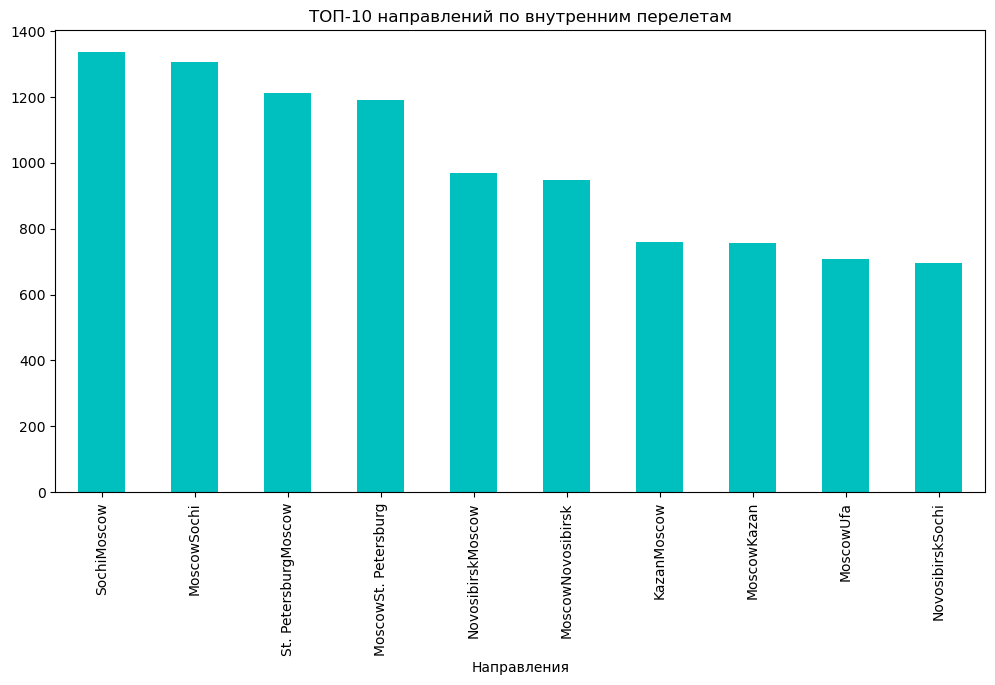

In [172]:
d = domest_f.city_city.value_counts().reset_index()
d[:10].plot(kind='bar',
        x='index',
        y='city_city',
        figsize=(12, 6),
        title='ТОП-10 направлений по внутренним перелетам',
        xlabel='Направления',
        legend=False,
        color='c')

In [173]:
#исправлено

### Матрица корреляций

In [176]:
new_dfo.head()

,issue_date,flight_date_loc,pax_type,revenue_amount,orig_city_code,dest_city_code,route_flight_type,ffp_flag,sale_type,year_month,month,season,delta_days,groups_inadv,iata_code_x,location_x,iata_code_y,location_y,pair_code,city_city
0,2021-10-01,2021-10-04,AD,370,OVB,LED,DOF,1,ONLINE,2021-10,10,autumn,3,lastmom,OVB,Novosibirsk,LED,St. Petersburg,OVBLED,NovosibirskSt. Petersburg
1,2021-10-01,2021-10-04,AD,390,KUF,MOW,DOF,1,ONLINE,2021-10,10,autumn,3,lastmom,KUF,Samara,NaN,Moscow,KUFMOW,SamaraMoscow
2,2021-10-01,2021-10-02,AD,840,OVB,VVO,DOF,1,OFFLINE,2021-10,10,autumn,1,lastmom,OVB,Novosibirsk,VVO,Vladivostok,OVBVVO,NovosibirskVladivostok
3,2021-10-01,2021-10-31,AD,330,UUD,OVB,DOF,1,ONLINE,2021-10,10,autumn,30,toomuch,UUD,Ulan-ude,OVB,Novosibirsk,UUDOVB,Ulan-udeNovosibirsk
4,2021-10-01,2021-10-10,AD,340,VOZ,MOW,DOF,0,OFFLINE,2021-10,10,autumn,9,less,VOZ,Voronezh,NaN,Moscow,VOZMOW,VoronezhMoscow


In [ ]:
#new_dfo.corr() не имеет смысла, так как почти все переменные у нас категориальные 

Построим матрицу корреляции по report_2

In [181]:
corr = report_2.corr()

#для красоты
corr.style.background_gradient(cmap='coolwarm')

,revenue_sum,ffp_amount,dof_type_amount,inf_type_amount,online_amount,offline_amount,passangers_number
revenue_sum,1.000000,0.539729,0.880093,-0.281689,0.699045,0.787094,0.778051
ffp_amount,0.539729,1.000000,0.852760,0.350155,0.937549,0.773457,0.918871
dof_type_amount,0.880093,0.852760,1.000000,-0.016935,0.934200,0.881018,0.964319
inf_type_amount,-0.281689,0.350155,-0.016935,1.000000,0.213194,0.265144,0.248374
online_amount,0.699045,0.937549,0.934200,0.213194,1.000000,0.782930,0.961505
offline_amount,0.787094,0.773457,0.881018,0.265144,0.782930,1.000000,0.923738
passangers_number,0.778051,0.918871,0.964319,0.248374,0.961505,0.923738,1.000000


Интерпретируем:
1. Сила связи между выручкой и ffp_amount (наличием программы лояльности) - **средняя**
2. Сила связи между выручкой и внутренними рейсами - **высокая**
3. Сила связи между выручкой и международными рейсами - **очень слабая отрицательная**
4. Сила связи между выручкой и онлайн оплатой - **средняя**
5. Сила связи между выручкой и оффлайн оплатой - **высокая**
6. Сила связи между выручкой и количеством пассажиров(продаж) - **высокая**

In [177]:
#исправления
cat_columns = new_dfo.select_dtypes(['object']).columns

#convert all categorical columns to numeric
new_dfo[cat_columns] = new_dfo[cat_columns].apply( lambda x: pd.factorize (x)[ 0 ])

In [180]:
corr_a = new_dfo.corr()
corr_a.style.background_gradient(cmap='coolwarm')

,pax_type,revenue_amount,orig_city_code,dest_city_code,route_flight_type,ffp_flag,sale_type,month,season,delta_days,iata_code_x,location_x,iata_code_y,location_y,pair_code,city_city
pax_type,1.000000,-0.085397,0.007457,0.005621,0.053461,-0.159292,-0.050302,-0.011251,0.034026,0.091579,0.007852,0.007203,0.004801,0.004907,0.016664,0.015920
revenue_amount,-0.085397,1.000000,0.092187,0.023044,0.098765,-0.047108,0.168159,-0.062748,0.245865,0.041020,0.104833,0.093803,0.025727,0.023200,0.209726,0.219491
orig_city_code,0.007457,0.092187,1.000000,-0.303537,0.221132,-0.065059,0.052639,0.000122,-0.007353,-0.013809,0.957303,0.994081,-0.310394,-0.307751,0.460686,0.453374
dest_city_code,0.005621,0.023044,-0.303537,1.000000,0.180300,-0.047694,0.030868,0.028224,-0.020299,-0.024412,-0.324983,-0.309730,0.963254,0.992001,0.388763,0.383140
route_flight_type,0.053461,0.098765,0.221132,0.180300,1.000000,-0.159329,0.103133,0.074326,-0.107561,-0.067341,0.202033,0.220960,0.161478,0.178902,0.313114,0.321017
ffp_flag,-0.159292,-0.047108,-0.065059,-0.047694,-0.159329,1.000000,-0.320700,-0.002951,-0.016039,0.022464,-0.057676,-0.063693,-0.041466,-0.046275,-0.091579,-0.088293
sale_type,-0.050302,0.168159,0.052639,0.030868,0.103133,-0.320700,1.000000,0.011308,-0.007140,-0.123163,0.053345,0.053254,0.029261,0.030659,0.075246,0.074332
month,-0.011251,-0.062748,0.000122,0.028224,0.074326,-0.002951,0.011308,1.000000,-0.341113,-0.110305,-0.003788,-0.000338,0.027126,0.028998,-0.000344,0.000113
season,0.034026,0.245865,-0.007353,-0.020299,-0.107561,-0.016039,-0.007140,-0.341113,1.000000,0.019162,-0.003099,-0.008577,-0.019191,-0.021988,0.035799,0.031689
delta_days,0.091579,0.041020,-0.013809,-0.024412,-0.067341,0.022464,-0.123163,-0.110305,0.019162,1.000000,-0.004990,-0.012514,-0.019096,-0.023029,0.012021,0.017927


***Получается, сила связи везде очень слабая и значит нет зависимости выручки от других признаков***\
если это вообще имеет смысл\

Попробую проверить зависимость выручки и типа оплаты через хи-квадрат тест\
Построим таблицу 2х2, где одним из факторов является тип перелета (онлайн/оффлайн), а другим - индикатор того, что выручка ниже или выше среднего значения (среднее = 433).

In [ ]:
online_df = new_dfo[new_dfo['sale_type'] == 'ONLINE']
offline_df = new_dfo[new_dfo['sale_type'] == 'OFFLINE']

a = online_df[online_df['revenue_amount'] < 433]['revenue_amount'].count()
b = online_df[online_df['revenue_amount'] >= 433]['revenue_amount'].count()

c = offline_df[offline_df['revenue_amount'] < 433]['revenue_amount'].count()
d = offline_df[offline_df['revenue_amount'] >= 433]['revenue_amount'].count()

list_of_list = [
    [a, b],
    [c, d],
]

dva_df = pd.DataFrame(list_of_list, 
                      columns = ['<mean', '>=mean'],
                      index = ['ONLINE', 'OFFLINE']) 
dva_df

Проверим гипотезу о наличии связи между типом оплаты и размером выручки.

***Нулевая гипотеза:*** переменные тип оплаты и размер выручки независимы\
***Альтернативная гипотеза:*** переменные тип оплаты и размер выручки связаны между собой

In [ ]:
st.chi2_contingency(dva_df)

Значение хи-квадрат (фактическое): 812.01\
Степени свободы: 1\
Уровень значимости: 0.05\
Табл значение: 3.84\

факт значение > табл значения\
Следовательно, нулевая гипотеза о независимости переменных отвергается. Значит, зависимость между типом оплаты и размером выручки имеется.\
Интересно, как теперь узнать, какая это зависимость